# Chapter 3: The Quantum Approximate Optimization Algorithm

*The quantum approximate optimization algorithm is the simplest variational quantum circuit and the one whose purpose is easiest to state: find the bit string that minimizes a cost. The chapter builds the pipeline from a combinatorial problem to a quadratic unconstrained binary optimization, from there to an Ising model and a diagonal cost Hamiltonian, and from the Hamiltonian to the alternating circuit of phase separators and transverse-field mixers, derived from adiabatic evolution by Trotterization and written out gate by gate. The single-edge instance is solved by hand, the algorithm is run on a ring and on a six-vertex graph, and its performance, landscape and gate cost are discussed. Gradients require the parameter-shift rule applied term by term, since the generators have many eigenvalues. Two electron spins in a double quantum dot, coupled by the exchange interaction, implement the one-edge instance natively, and the selection of a portfolio of stocks from real price data shows the pipeline on a constrained problem, with the penalty method, its tuning and the connection to thermal states. The chapter closes by reading QAOA as a machine-learning model: a clustering algorithm, a quantum neural network with a problem-fixed architecture, a feature map and a sampler.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

The quantum support-vector machine of Chapter 2 used the
quantum computer for one thing only, to evaluate a kernel; the learning
was classical and convex, and, the trainable kernels of its last
section apart, there were no parameters on the quantum side. This chapter introduces the other way of using the
machine, which the rest of the book will follow: a circuit with
adjustable angles, an expectation value that depends on them, and a
classical optimizer that moves the angles downhill. The *quantum
approximate optimization algorithm* (QAOA) of Farhi, Goldstone and
Gutmann [Farhi2014] is the simplest and the most structured
example of such a variational circuit, and it is also the one whose
purpose is easiest to state: it looks for the bit string that minimizes
a cost function, by preparing a quantum state whose measurement
outcomes are concentrated on good bit strings.

The algorithm is a bridge in two directions. Towards physics, it is a
variational eigensolver for an Ising Hamiltonian, the problem is
written as a classical spin glass, and its ansatz is the
Trotterized form of adiabatic quantum evolution, so that the reader of
the companion volume [QCbook] will recognize every ingredient:
its chapter on variational quantum algorithms introduces QAOA in a
section of its own, after the variational principle, the ansätze,
the measurement of a Pauli sum and the parameter-shift rule, and the
present chapter continues from there, with the relation between its
sign convention for the cost Hamiltonian and ours made explicit in
Section *From a cost function to a Hamiltonian*.
Towards machine learning, it is a parametrized circuit trained by
gradient descent on a cost, the data of a problem enter through the
Hamiltonian, and the variational classifiers and generative models of
Chapters 4 and 5 differ from it only in
where the data and the parameters sit. We develop both directions.

The chapter is organized as follows. Section *From a cost function to a Hamiltonian* sets up
the problem: combinatorial optimization over bit strings, its quadratic
unconstrained binary form (QUBO), the change of variables that turns it
into an Ising model, and the cost Hamiltonian, with MaxCut as the
running example. Section *The algorithm* defines the algorithm, derives
its ansatz from adiabatic evolution by Trotterization, and gives the
circuit gate by gate. Section *The algorithm at work* solves the smallest
instance, a single edge, by hand, runs the algorithm on a four-vertex
ring and a six-vertex graph, and discusses what is known about its
performance, its landscape and its cost in gates. Section *Gradients*
is about gradients, where the parameter-shift rule of Chapter 2
meets a complication, generators with many eigenvalues, and where a
simple per-term rule resolves it. Section *A physical register: two electrons in a double quantum well* leaves
the abstract register for a physical one: two electrons in a double
quantum well whose exchange interaction implements the cost unitary,
following a recent two-qubit experiment [Roscher2026].
Section *An application: selecting a portfolio* applies the pipeline to a problem outside
physics, the selection of a portfolio of stocks from real price data,
and uses it to discuss constraints, penalties and the connection to the
statistical mechanics of spin glasses. Section *QAOA as a machine-learning model* returns
to the question of the book and reads QAOA as a machine-learning model,
with clustering as the example. The programs are in
`BookPrograms/chapter3/`: a `QUBO` and an `Ising`
class, a `QAOA` class on the simulator of the earlier chapters
with the three gradient rules, and the scripts of the experiments.
Every number quoted below is printed by one of them.


## From a cost function to a Hamiltonian

**Binary optimization.** 
A combinatorial optimization problem asks for the bit string
$\vec{x}=(x_1,\dots,x_n)\in\{0,1\}^n$ that minimizes a cost function
$C:\{0,1\}^n\to\mathbb{R}$,

$$
\vec{x}^{*}=\arg\min_{\vec{x}\in\{0,1\}^n}C(\vec{x}) .\tag{3.1}
$$

The search space has $2^n$ elements, and for the problems of interest,
the *NP-hard* ones, no algorithm is known that finds $\vec{x}^{*}$
in time polynomial in $n$ for every instance. One settles for
approximations, and measures their quality by the *approximation
ratio*, the value achieved divided by the optimum; for a minimization
with negative costs, which is how MaxCut will appear below, the ratio
$\alpha=C(\vec{x})/C(\vec{x}^{*})\le1$, and the closer to one the
better.

**QUBO.** 
A large class of such problems can be written with a cost that is
quadratic in the bits,

$$
C(\vec{x})=\vec{x}^{T}\matr{Q}\vec{x}+c_0=\sum_{i}Q_{ii}x_i+\sum_{i<j}2Q_{ij}\,x_ix_j+c_0 ,\tag{3.2}
$$

with a real symmetric matrix $\matr{Q}$ and a constant $c_0$; since
$x_i^2=x_i$ for a bit, the diagonal of $\matr{Q}$ carries the linear
terms. This is *quadratic unconstrained binary optimization*,
QUBO [Kochenberger2014], and Lucas's catalog [Lucas2014]
shows how partitioning, covering, coloring, scheduling and
satisfiability problems are brought into this form, constraints
included, by adding penalty terms. QUBO is itself NP-hard, so nothing
is lost in generality, and everything is gained in uniformity: a
single algorithm for Eq. (3.2) is an algorithm for all of
them.

**From bits to spins.** 
The substitution

$$
x_i=\frac{1-z_i}{2},\qquad z_i=1-2x_i\in\{-1,+1\},\tag{3.3}
$$

turns a bit into a classical spin, with $x_i=0$ the spin $z_i=+1$ and
$x_i=1$ the spin $z_i=-1$. Inserting it into Eq. (3.2) and
collecting the terms by their degree in the spins gives an
*Ising model*,

$$
C(\vec{x})=H(\vec{z})=\sum_{i}h_iz_i+\sum_{i<j}J_{ij}\,z_iz_j+c ,\tag{3.4}
$$

with, for symmetric $\matr{Q}$,

$$
J_{ij}=\frac{Q_{ij}}{2},\qquad
h_i=-\frac{Q_{ii}}{2}-\sum_{j\ne i}\frac{Q_{ij}}{2},\qquad
c=c_0+\sum_i\frac{Q_{ii}}{2}+\sum_{i<j}\frac{Q_{ij}}{2} .\tag{3.5}
$$

The derivation is a few lines (Exercise 3.1): the product
$x_ix_j=(1-z_i)(1-z_j)/4$ contributes $z_iz_j/4$, $-z_i/4$, $-z_j/4$
and a constant, each appearing twice in the double sum of
Eq. (3.2), and the linear term $Q_{ii}x_i$ contributes
$-Q_{ii}z_i/2$ and $Q_{ii}/2$. Minimizing $C$ over bit strings is
finding the ground state of the Ising model, a problem that
statistical physics has studied for a century, and whose hardness,
for couplings $J_{ij}$ of both signs that cannot all be satisfied at
once, is the *frustration* of a spin glass.
The class `QUBO` of `qubo.py` carries out the substitution
and the class `Ising` lists the energies of all bit strings:


In [2]:
import numpy as np
from qubo import QUBO, bitstrings
q = QUBO([[1, -2], [-2, 1]])                  # C(x) = x1 + x2 - 4 x1 x2, Table 3-qubo
ising = q.to_ising()                          # Eq. (3-qubotoising)
print("J_12 =", ising.J[0, 1], " h =", ising.h, " const =", ising.const)
for x, c, e in zip(bitstrings(2), q.costs(), ising.energies()):
    print(x, 1 - 2 * x, c, e)                 # bits, spins, C(x), H(z) + const
ring = QUBO.maxcut(4, [(0, 1), (1, 2), (2, 3), (3, 0)]).to_ising()
print("ring: ground energy", ring.ground_state()[0], "= minus", 4, "cut edges")


J_12 = -1.0  h = [0.5 0.5]  const = 0.0
[0 0] [1 1] 0.0 0.0
[0 1] [ 1 -1] 1.0 1.0
[1 0] [-1  1] 1.0 1.0
[1 1] [-1 -1] -2.0 -2.0
ring: ground energy -4.0 = minus 4 cut edges


| $\vec{x}$ | $\vec{z}$ | $C(\vec{x})$ | $H(\vec{z})+c$ |
|---|---|---|---|
| $(0,0)$ | $(+1,+1)$ | $0$ | $0$ |
| $(0,1)$ | $(+1,-1)$ | $1$ | $1$ |
| $(1,0)$ | $(-1,+1)$ | $1$ | $1$ |
| $(1,1)$ | $(-1,-1)$ | $-2$ | $-2$ |

*Table 3.1: The QUBO with $\matr{Q}=\bigl(\begin{smallmatrix}1&-2\\-2&1\end{smallmatrix}\bigr)$,
$C(\vec{x})=x_1+x_2-4x_1x_2$, and its Ising form
$H(\vec{z})=-z_1z_2+\tfrac12(z_1+z_2)$, $c=0$, by
Eq. (3.5). From `qubo.py`.*

**From spins to qubits.** 
A classical spin $z_i=\pm1$ is the eigenvalue of the Pauli operator
$Z_i$ on the computational basis states $\vert0\rangle$ and
$\vert1\rangle$ of qubit $i$, and the substitution $z_i\to Z_i$ turns
Eq. (3.4) into the *cost Hamiltonian*

$$
H_C=\sum_{i}h_iZ_i+\sum_{i<j}J_{ij}\,Z_iZ_j+c\,I ,
\qquad H_C\vert\vec{x}\rangle=C(\vec{x})\vert\vec{x}\rangle .\tag{3.6}
$$

It is diagonal in the computational basis, every bit string is an
eigenstate with its cost as the eigenvalue, and the optimal bit string
is the ground state. The whole of the chapter is about preparing a
state of $n$ qubits that has a large overlap with that ground state.
We use the conventions of Chapter 1: qubit $0$ is the
leftmost factor, $\vert0\rangle\leftrightarrow z=+1\leftrightarrow x=0$.

**MaxCut.** 
The example that every discussion of QAOA starts from is
*MaxCut*. Given a graph $G=(V,E)$ with weights $w_{ij}$ on its
edges, split the vertices into two sets so that the total weight of
the edges running between the sets, the *cut*, is as large as
possible. With $x_i=1$ for the vertices of one set, an edge is cut
when $x_i\ne x_j$, which the quadratic expression
$x_i+x_j-2x_ix_j$ detects, so the cut and the cost to be minimized are

$$
\mathrm{Cut}(\vec{x})=\sum_{(i,j)\in E}w_{ij}\left(x_i+x_j-2x_ix_j\right),
\qquad
C(\vec{x})=-\mathrm{Cut}(\vec{x}) .\tag{3.7}
$$

The substitution of Eq. (3.3) gives
$x_i+x_j-2x_ix_j=(1-z_iz_j)/2$ and therefore

$$
H_C=-\frac{1}{2}\sum_{(i,j)\in E}w_{ij}\left(I-Z_iZ_j\right),\tag{3.8}
$$

an antiferromagnetic Ising model, $J_{ij}=w_{ij}/2$, without fields
and with the constant $c=-\frac12\sum w_{ij}$; the ground-state energy is
minus the maximum cut. MaxCut is NP-hard; the best classical algorithm
with a guarantee, the semidefinite relaxation of Goemans and Williamson
[GoemansWilliamson1995], achieves an approximation ratio of
$0.878$ on every graph, and it is widely believed that no polynomial
algorithm does better in the worst case. Our running example is the
ring of four vertices, $C_4$, with edges $(0,1)$, $(1,2)$, $(2,3)$,
$(3,0)$ and unit weights, whose Hamiltonian
$H_C=\frac12(Z_0Z_1+Z_1Z_2+Z_2Z_3+Z_3Z_0)-2$ has the ground energy
$-4$, all four edges cut, at the two alternating strings $0101$ and
$1010$; the program `qubo.py` checks this against the cut of
every bit string. We follow the sign convention of
Eq. (3.8), minimizing $\langle H_C\rangle$, throughout
the chapter, since it is the one in which QUBO, the double well and the
portfolio all appear; the original paper and the companion volume
maximize the cut operator $-H_C$ instead, which amounts to the sign
change $\gamma\to-\gamma$ in everything that follows.


## The algorithm

**The variational principle.** 
For any state, $\langle\psi\vert H_C\vert\psi\rangle\ge E_0$, with
equality only in the ground-state eigenspace, and the expectation value
of a diagonal operator is the average cost over the measurement
distribution,

$$
E=\langle\psi\vert H_C\vert\psi\rangle=\sum_{\vec{x}}C(\vec{x})\,\vert\langle\vec{x}\vert\psi\rangle\vert^2 .\tag{3.9}
$$

A variational algorithm restricts $\vert\psi\rangle$ to a family
$\vert\psi(\vec{\theta})\rangle$ prepared by a circuit, minimizes
Eq. (3.9) over $\vec{\theta}$ with a classical
optimizer, and reads out bit strings from the optimized state. The
variational quantum eigensolver of the companion volume [QCbook]
does this for molecular and nuclear Hamiltonians with chemistry-inspired
or hardware-efficient circuits. QAOA is a variational quantum
eigensolver whose circuit is dictated by the problem.

**The mixer and the ansatz.** 
The second ingredient is the *mixing Hamiltonian*

$$
H_M=\sum_{i}X_i ,\tag{3.10}
$$

a transverse field. It does not commute with $H_C$, so that alternating
the two generates transitions between bit strings, and the ground
state of $-H_M$ is the uniform superposition
$\vert+\rangle^{\otimes n}=H^{\otimes n}\vert0\rangle^{\otimes n}=2^{-n/2}\sum_{\vec{x}}\vert\vec{x}\rangle$,
which is also the state of complete ignorance about the answer. The
depth-$p$ QAOA state is

$$
\vert\psi_p(\vec{\gamma},\vec{\beta})\rangle
=\prod_{k=1}^{p}e^{-i\beta_kH_M}\,e^{-i\gamma_kH_C}\,\vert+\rangle^{\otimes n},\tag{3.11}
$$

with the factor $k=1$ acting first, and the $2p$ angles
$\vec{\gamma}=(\gamma_1,\dots,\gamma_p)$,
$\vec{\beta}=(\beta_1,\dots,\beta_p)$ are the variational parameters.
Each layer first applies the *phase separator*
$U_C(\gamma)=e^{-i\gamma H_C}$, which is diagonal and writes the cost of
every bit string into its phase,
$U_C(\gamma)\vert\vec{x}\rangle=e^{-i\gamma C(\vec{x})}\vert\vec{x}\rangle$,
and then the *mixer* $U_M(\beta)=e^{-i\beta H_M}=\bigotimes_iR_x(2\beta)$,
a product of single-qubit rotations, which turns the phases into
amplitudes by interference. The algorithm minimizes
$E_p(\vec{\gamma},\vec{\beta})=\langle\psi_p\vert H_C\vert\psi_p\rangle$,
and the claim of Farhi *et al.* is that
$\min E_p\to E_0$ as $p\to\infty$. The landscape is $2\pi$-periodic in
every $\gamma_k$ when the costs are integers, as in unweighted MaxCut,
and $\pi$-periodic in every $\beta_k$, since $e^{-i\pi H_M}=(-1)^nI$; for
a cost without field terms, such as Eq. (3.8), the
period in $\beta$ is even $\pi/2$, since $e^{-i(\pi/2)H_M}=(-i)^nX^{\otimes n}$
is a global phase times the flip of all bits, which leaves such an $H_C$
invariant.

**Where the ansatz comes from.** 
The form of Eq. (3.11) is not a guess. Adiabatic quantum
computation [Farhi2001,Albash2018] prepares the ground state of
$H_C$ by starting in the ground state of $H_M$ and evolving under the
interpolating Hamiltonian

$$
H(s)=(1-s)\,(-H_M)+s\,H_C,\qquad s=t/T\in[0,1] ,\tag{3.12}
$$

for a time $T$ long compared with the inverse square of the smallest
gap of $H(s)$; the adiabatic theorem then keeps the system in the
instantaneous ground state, and the final state is the answer. (The sign
of $H_M$ is chosen so that $\vert+\rangle^{\otimes n}$ is its ground
state; it is a convention, since $\beta\to-\beta$ undoes it.)
Discretize the evolution into $p$ steps of length $\Delta t=T/p$ at
$s_k=k/p$, and split each step by the first-order Trotter formula of
the companion volume,

$$
e^{-i\Delta t\,H(s_k)}=e^{+i\Delta t\,(1-s_k)H_M}\,e^{-i\Delta t\,s_kH_C}+\bigO\!\left(\Delta t^2\,[H_C,H_M]\right).\tag{3.13}
$$

The product over $k$ is exactly Eq. (3.11) with the
*schedule* $\gamma_k=s_k\Delta t$, $\beta_k=-(1-s_k)\Delta t$. QAOA
takes this circuit and frees the angles: instead of following the
schedule, which is only guaranteed to work for a very long $T$ and
therefore a very large $p$, it lets a classical optimizer choose
$\vec{\gamma},\vec{\beta}$ for the $p$ at hand. At $p\to\infty$ the
adiabatic schedule is among the admissible parameters and the
minimum of $E_p$ reaches $E_0$; at small $p$ the optimized angles are
usually nothing like a schedule, and the algorithm is a different
object, closer to a learned control protocol [Brady2021,Zhou2020]
than to an approximation of adiabatic evolution. The commutator in
Eq. (3.13) is what makes the circuit non-trivial: for
MaxCut, with $[Z_a,X_b]=2i\delta_{ab}Y_a$,
$[H_C,H_M]=i\sum_{(i,j)\in E}w_{ij}(Y_iZ_j+Z_iY_j)$, and it is this
operator that generates entanglement between the qubits of an edge.

**The circuit.** 
Both unitaries have an exact, short circuit. Each term of $H_C$ is a
Pauli string that is diagonal in the computational basis, and the
terms commute, so $U_C(\gamma)$ is a product of one gate per term:
$e^{-i\gamma h_iZ_i}=R_z(2\gamma h_i)$ for a field, and for a coupling

$$
e^{-i\gamma J_{ij}Z_iZ_j}=\mathrm{CNOT}_{ij}\;R_z^{(j)}(2\gamma J_{ij})\;\mathrm{CNOT}_{ij},\tag{3.14}
$$

the same gadget as the ZZ feature map of Chapter 2: the
first CNOT writes the parity $z_iz_j$ into qubit $j$, the rotation
applies the phase, and the second CNOT restores the qubit. The mixer
is $R_x(2\beta)$ on every qubit. Figure 3.1 draws one
layer for a path of three vertices, and the gate count of a layer is

$$
N_{\mathrm{CNOT}}=2\,\vert E\vert,\qquad N_{R_z}=\vert E\vert+n_h,\qquad N_{R_x}=n ,\tag{3.15}
$$

with $n_h$ the number of nonzero fields, plus the $n$ Hadamards of the
initial state. Every gate of the phase separator can be applied in
parallel with the gates of the edges that share no vertex, so that the
depth of a layer is set by the degree of the graph rather than by its
size. On the simulator, we exploit a different structure: the phase
separator is an elementwise phase on the $2^n$ amplitudes, and the mixer
is diagonal in the $X$ basis,

$$
e^{-i\beta\sum_qX_q}=H^{\otimes n}\,e^{-i\beta\sum_qZ_q}\,H^{\otimes n},\tag{3.16}
$$

so that one layer costs two Hadamard transforms and two phases. This is
how the class `QAOA` of `qaoa.py` prepares
Eq. (3.11); stripped of the bookkeeping for the
parameter shifts of Section *Gradients*, its core is


In [3]:
import numpy as np
from qubo import QUBO, bitstrings
ising = QUBO.maxcut(4, [(0, 1), (1, 2), (2, 3), (3, 0)]).to_ising()
n, cost = ising.n, ising.energies()           # C(z) for every bit string
z = 1 - 2 * bitstrings(n)                     # z_q = +-1 per bit string and qubit
H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
Hn = H1
for _ in range(n - 1):
    Hn = np.kron(Hn, H1)                      # H^{(x)n}

def qaoa_state(gammas, betas):
    psi = np.full(2 ** n, 2 ** (-n / 2), dtype=complex)        # |+>^n
    for gamma, beta in zip(gammas, betas):
        psi = np.exp(-1j * gamma * cost) * psi                 # phase separator
        psi = Hn @ (np.exp(-1j * beta * z.sum(1)) * (Hn @ psi))  # mixer, Eq. (3-mixerwht)
    return psi

psi = qaoa_state([np.pi / 4], [3 * np.pi / 8])
print("E =", np.real(np.vdot(psi, cost * psi)))   # -3: three of four edges cut


E = -2.999999999999997


![One layer of the QAOA circuit for MaxCut on the path  qubit  on the to](../../BookFigures/chapter3/3-circuit.png)

*Figure 3.1: One layer of the QAOA circuit for MaxCut on the path $0-1-2$ (qubit $0$ on the top wire). After the Hadamards that prepare $\vert+\rangle^{\otimes3}$, each edge contributes the gadget of Eq. (3.14), CNOT, $R_z(2\gamma J_{ij})=R_z(\gamma w_{ij})$ on the target, CNOT, the constant of $H_C$ being a global phase; the mixer is one $R_x(2\beta)$ per qubit. Deeper circuits repeat the two blocks with new angles before the measurement.*

**The loop.** 
The classical optimizer sees only the function
$E_p(\vec{\gamma},\vec{\beta})$, estimated on a quantum computer by
preparing the state, measuring all qubits, and averaging the cost of
the outcomes over $S$ shots, with the statistical error
$\sigma_C/\sqrt{S}$ of Chapter 1. The optimizer may be
gradient-free (Nelder--Mead, COBYLA, or the stochastic approximation of
the companion volume) or use the gradients of
Section *Gradients*; since the landscape has many local
minima, it is run from several random starting points, and since the
optimal angles at depth $p$ are a good start for depth $p+1$
[Zhou2020], we also start the depth-$(p+1)$ search from the
depth-$p$ optimum with one layer appended (the *warm start*). The
output is not the energy but a bit string: the optimized state is
sampled, and the best bit string among the samples is returned. Since
the state is a superposition, this best string is usually better than
the average, and the probability of sampling an optimal string is a
more honest figure of merit than the approximation ratio of the energy.


## The algorithm at work

### One edge, by hand

The smallest instance, two vertices and one edge, can be solved
completely in closed form, and the calculation shows how the two layers
of the circuit cooperate. With $H_C=-\frac12(I-Z_0Z_1)$ and
$H_M=X_0+X_1$ the $p=1$ state is
$\vert\psi\rangle=e^{-i\beta(X_0+X_1)}e^{-i\gamma H_C}\vert{+}{+}\rangle$,
and we need $\langle Z_0Z_1\rangle$. Rather than computing the state,
we move the operator through the circuit, the Heisenberg picture. The
mixer rotates each $Z$ about the $x$ axis,

$$
e^{i\beta X}Ze^{-i\beta X}=Z\,e^{-2i\beta X}=\cos(2\beta)\,Z+\sin(2\beta)\,Y ,\tag{3.17}
$$

(using $ZX=iY$ and that $Z$ anticommutes with $X$), so that

$$
U_M^{\dagger}Z_0Z_1U_M=\cos^2(2\beta)\,Z_0Z_1+\sin(2\beta)\cos(2\beta)\,(Z_0Y_1+Y_0Z_1)+\sin^2(2\beta)\,Y_0Y_1 .
$$

The phase separator, $e^{-i\gamma H_C}=e^{i\gamma/2}e^{-i\gamma Z_0Z_1/2}$,
commutes with $Z_0Z_1$ and with $Y_0Y_1$ and leaves them unchanged; its
generator $Z_0Z_1$ anticommutes with $Z_0Y_1$, for which

$$
U_C^{\dagger}\,Z_0Y_1\,U_C=Z_0Y_1\,e^{-i\gamma Z_0Z_1}=\cos\gamma\,Z_0Y_1-i\sin\gamma\,Z_0Y_1Z_0Z_1=\cos\gamma\,Z_0Y_1+\sin\gamma\,X_1 ,
$$

since $Y_1Z_1=iX_1$, and likewise $Y_0Z_1\to\cos\gamma\,Y_0Z_1+\sin\gamma\,X_0$.
In $\vert{+}{+}\rangle$ every operator containing a $Y$ or a $Z$ has
expectation zero and $\langle X_0\rangle=\langle X_1\rangle=1$, so that
$\langle Z_0Z_1\rangle=2\sin(2\beta)\cos(2\beta)\sin\gamma=\sin(4\beta)\sin\gamma$,
and

$$
E_1(\gamma,\beta)=-\frac{1}{2}\left(1-\langle Z_0Z_1\rangle\right)=-\frac{1}{2}+\frac{1}{2}\sin(4\beta)\sin\gamma .\tag{3.18}
$$

The minimum $E_1=-1$, the exact ground energy, is reached at
$\sin(4\beta)\sin\gamma=-1$, for instance $\beta^{*}=\pi/8$,
$\gamma^{*}=3\pi/2$ (equivalently $-\pi/2$). The program
`qaoa.py` checks Eq. (3.18) against the simulator
on a grid, to $10^{-15}$, and prints the optimal state,
$\frac{1}{\sqrt2}(\vert01\rangle+\vert10\rangle)$ up to a phase: the
equal superposition of the two optimal cuts, a Bell state, with a
single measurement giving an optimal bit string with certainty. One
layer suffices because the problem has one edge; we shall return to
this state in Section *A physical register: two electrons in a double quantum well*, where the two qubits are
two electron spins.

The same Heisenberg calculation on a general graph gives the
$p=1$ energy edge by edge [Farhi2014]: the expectation of
$Z_iZ_j$ depends only on the edges adjacent to $(i,j)$, and for a
triangle-free graph in which $i$ and $j$ have degrees $d_i$ and $d_j$,
$\langle Z_iZ_j\rangle=\frac12\sin(4\beta)\sin\gamma\,(\cos^{d_i-1}\gamma+\cos^{d_j-1}\gamma)$,
which for the ring, $d=2$, gives

$$
E_1^{\mathrm{ring}}(\gamma,\beta)=-2+\sin(4\beta)\sin(2\gamma)
\qquad\text{for }C_4 ,\tag{3.19}
$$

also verified by `maxcut.py`. Its minimum is $-3$: one layer
cuts three of the four edges, an approximation ratio of $3/4$. This
*locality* is general. At depth $p$ the expectation of an edge
term depends only on the subgraph within distance $p$ of the edge, its
light cone, because each layer of the circuit spreads the operator by
one edge; the QAOA energy at fixed $p$ is therefore a sum of local
contributions, and the algorithm cannot see global structure, such as
whether the graph is bipartite, until $p$ is comparable to the
diameter of the graph [FarhiHarrow2016,Bravyi2020].

### The ring and a six-vertex graph

Table 3.2 and Fig. 3.2 show the algorithm on
the ring $C_4$, with eight random starts of the BFGS optimizer per
depth and the warm start from the previous depth. At $p=1$ the
optimizer finds $\gamma=3\pi/4$, $\beta=\pi/8$ (mod the periods), one of
the two minima of Eq. (3.19), with $E=-3$ and a probability
$0.53$ of reading one of the two optimal strings; the landscape in the
first panel has four extrema, two equivalent minima and two equivalent
maxima,
related by the symmetries $(\gamma,\beta)\to(\gamma+\pi/2,\beta+\pi/4)$
of the ring. At $p=2$ the state is exactly the superposition of the
two optimal cuts, $E=-4$ and $P_{\mathrm{opt}}=1$: the light cone of two
layers covers the whole ring, and two layers are enough to prepare the
ground state. This is the general pattern on small bipartite graphs and
should not be mistaken for a property of the algorithm.

|  | ring $C_4$ |  |  | six-vertex graph |  |  |
|---|---|---|---|---|---|---|
| $p$ | $\langle H_C\rangle$ | ratio | $P_{\mathrm{opt}}$ | $\langle H_C\rangle$ | ratio | $P_{\mathrm{opt}}$ |
| 1 | $-3.000$ | 0.750 | 0.531 | $-5.469$ | 0.781 | 0.187 |
| 2 | $-4.000$ | 1.000 | 1.000 | $-6.150$ | 0.879 | 0.364 |
| 3 | $-4.000$ | 1.000 | 1.000 | $-6.455$ | 0.922 | 0.542 |
| 4 |  |  |  | $-6.680$ | 0.954 | 0.768 |

*Table 3.2: QAOA on MaxCut of the ring $C_4$ (maximum cut 4) and of the
six-vertex graph with edges $(0,1),(1,2),(2,3),(3,4),(4,5),(5,0),(0,2),(1,4)$
(maximum cut 7 of 8). Energy $\langle H_C\rangle$, approximation ratio
$\langle H_C\rangle/E_0$ and probability of an optimal string at the
optimized angles, eight random starts plus the warm start. From
`maxcut.py`.*

![MaxCut on the ring C4. Left the p1 landscape E1gamma,beta of Eq. 3.19 ](../../BookFigures/chapter3/ring.png)

*Figure 3.2: MaxCut on the ring $C_4$. Left: the $p=1$ landscape $E_1(\gamma,\beta)$ of Eq. (3.19) with the optimum found by the optimizer (star). Right: the output distributions of the optimized states for $p=1,2,3$; the two optimal strings are in red. From `maxcut.py`.*

The second half of Table 3.2 is a graph with a triangle,
the six-ring with the chords $(0,2)$ and $(1,4)$, which is not
bipartite, so that no cut takes all eight edges; the maximum is seven,
reached by two strings. Here the ratio climbs from $0.78$ at $p=1$ to
$0.95$ at $p=4$, and the probability of sampling an optimal string from
$0.19$ to $0.77$, with no sign of the exact solution at any depth we
tried. The light-cone argument says why: already a two-layer circuit
on a graph of diameter two can see everything, but seeing is not solving,
and the optimized angles at small $p$ balance the terms of
Eq. (3.9) rather than satisfying them. Each layer on
this graph costs 16 CNOTs, 8 $R_z$ and 6 $R_x$ gates, by
Eq. (3.15).

### Performance, landscape and cost

What is known in general is less than one might hope. At $p=1$ the
ratio for unweighted $3$-regular graphs is at least $0.6924$
[Farhi2014], below the $0.878$ of Goemans and Williamson, and
the bounds improve slowly with $p$; for worst-case instances the
locality argument shows that a constant $p$ cannot beat the classical
guarantee, and that $p$ must grow with the size of the graph
[Bravyi2020]. On typical instances the algorithm does much better
than its worst-case bounds, and the $p$ needed for a given ratio has
been studied numerically up to tens of qubits [Zhou2020]; an
early large hardware demonstration ran MaxCut on up to 23 qubits
[Harrigan2021], with the noise of the device visible in a
performance that peaked at $p=3$ and decreased beyond.
Whether QAOA at any feasible depth offers an advantage over the best
classical heuristics for optimization is an open question, and the
case for it rests on the facts that the circuit is shallow, that its
output cannot in general be sampled classically even at $p=1$
[FarhiHarrow2016], and that it is a natural fit for the
hardware.

The landscape $E_p(\vec{\gamma},\vec{\beta})$ is a trigonometric
polynomial in the angles, smooth and periodic. At $p=1$ it is simple
enough to scan, as Fig. 3.2 did, and often to write down.
As $p$ grows it acquires the many local minima of a glassy function,
and the optimization becomes the hard part of the algorithm; the warm
start and the observation that the optimal angles vary smoothly with
$p$ and transfer between instances of the same class
[Zhou2020,Egger2021] are the practical answers. The barren
plateaus of Chapter 1 are milder here than for a generic
circuit: the cost is a sum of two-body terms, the circuit has only two
parameters per layer, and for constant $p$ the gradient of an edge
term involves only its light cone, so that the variance of the
gradient decays polynomially rather than exponentially with $n$. They
do return when $p$ grows with $n$.

Finally, the cost in gates. A layer costs the $2\vert E\vert+\vert E\vert+n$
gates of Eq. (3.15), and with a two-qubit error rate
$\epsilon$ the fidelity of the whole circuit decays as
$(1-\epsilon)^{2p\vert E\vert}$. For a graph with $n=100$ vertices and
$\vert E\vert=500$ edges and $\epsilon=10^{-3}$, a single layer already
has a thousand CNOTs and a fidelity of $e^{-1}$; the depths of
Table 3.2 are affordable only on small graphs or with
much better gates, and the demonstrations on hardware have accordingly
used small $p$ and error mitigation. This arithmetic, more than any
theorem, sets the near-term scope of the algorithm.


## Gradients

The optimizers themselves, gradient descent with and without momentum,
Adam and BFGS, are those of the optimization chapter of the
machine-learning text [MLbook], implemented in
`common/optimize.py`; what is specific to a circuit is how the
gradient is obtained. The optimizer needs $\partial E/\partial\gamma_k$ and
$\partial E/\partial\beta_k$, and the parameter-shift rule of
Chapter 2 seems to supply them: for a gate $e^{-i\theta P}$
with $P^2=I$, $\partial_\theta f=f(\theta+\pi/4)-f(\theta-\pi/4)$ (the
rule of Chapter 2 written for $e^{-i\theta P}$ rather
than $e^{-i\theta P/2}$, which halves the shift and removes the factor
$\tfrac12$). The
generators here are $H_C$ and $H_M$, and neither squares to the
identity. The naive application of the rule to the whole angle,

$$
\frac{\partial E}{\partial\gamma_k}\overset{?}{=}E(\gamma_k+\pi/4)-E(\gamma_k-\pi/4),\tag{3.20}
$$

is therefore not a derivative but a finite difference with a large
step, and Fig. 3.3 shows how wrong it is on the
six-vertex graph: for $\gamma$ it has the right sign most of the time
and the wrong magnitude everywhere, and for $\beta$ it returns zero
along the whole line, because the two shifted mixers differ by
$e^{-i(\pi/2)\sum_qX_q}=(-i)^nX^{\otimes n}$, the flip of all bits, which
leaves a field-free $H_C$ invariant, so that $E(\beta+\pi/4)=E(\beta-\pi/4)$
identically.

The correct rule follows from the structure of the unitaries. The
phase separator is a product of commuting gates, one per Pauli term
$P_a$ of $H_C=\sum_ac_aP_a$, each with its own angle $\theta_a=\gamma c_a$,
and the mixer is a product of one gate per qubit with angle $\beta$.
The chain rule gives

$$
\frac{\partial E}{\partial\gamma_k}=\sum_ac_a\left[E(\theta_{a}^{(k)}+\tfrac{\pi}{4})-E(\theta_{a}^{(k)}-\tfrac{\pi}{4})\right],
\qquad
\frac{\partial E}{\partial\beta_k}=\sum_{q}\left[E(\beta_{q}^{(k)}+\tfrac{\pi}{4})-E(\beta_{q}^{(k)}-\tfrac{\pi}{4})\right],\tag{3.21}
$$

where the shift is applied to the angle of one term, or of one qubit,
in layer $k$ only, with all other angles at their values. Each
evaluation is a circuit that differs from the original by one gate
angle, so the rule is exact and hardware-compatible
[Schuld2019gradients,Crooks2019,Wierichs2022], and it costs
$2(K+n)$ energy evaluations per layer, with $K$ the number of terms;
Fig. 3.3 shows it agreeing with central finite
differences to $10^{-9}$. (The finite-difference gradient is exact on a
noiseless simulator and useless on hardware, where a step small enough
to approximate the derivative is swamped by shot noise; the shift rule
uses steps of order one.) Terms that commute and act on disjoint
qubits can share a shift, which brings the cost down to the number of
commuting groups, and for the two angles per layer of QAOA the whole
gradient is cheap compared with the gradient of a generic circuit
with hundreds of parameters.
In `qaoa.py` the rule reads, with `self.terms` the list of
terms $(c_a,P_a,\dots)$ and `energy(params, shift)` evaluating the circuit with
one angle shifted:


In [4]:
import numpy as np
from qubo import QUBO
from qaoa import QAOA
q = QAOA(QUBO.maxcut(4, [(0, 1), (1, 2), (2, 3), (3, 0)]).to_ising(), p=1)
x, s = np.array([0.8, 0.5]), np.pi / 4

def gradient_shift(q, x):                      # Eq. (3-pertermshift)
    g = np.zeros(2 * q.p)
    for k in range(q.p):
        for a, (c, d, _) in enumerate(q.terms):
            g[k] += c * (q.energy(x, (k, "cost", a, +s)) - q.energy(x, (k, "cost", a, -s)))
        for qubit in range(q.n):
            g[q.p + k] += q.energy(x, (k, "mixer", qubit, +s)) - q.energy(x, (k, "mixer", qubit, -s))
    return g

print(gradient_shift(q, x), q.gradient_fd(x), q.gradient_global_shift(x))


[-0.0531021  -1.66387757] [-0.0531021  -1.66387757] [-0.0531021  0.       ]


![Gradients of the p1 energy of the six-vertex graph along the line beta](../../BookFigures/chapter3/gradients.png)

*Figure 3.3: Gradients of the $p=1$ energy of the six-vertex graph along the line $\beta=0.4$: central finite differences, the per-term parameter-shift rule of Eq. (3.21), and the naive global shift of Eq. (3.20), for $\gamma$ (left) and $\beta$ (middle). Right: plain gradient descent with the shift-rule gradient against BFGS from the same random start at $p=2$, with the cost counted in energy evaluations (a gradient costs $2p(K+n)=56$ of them). From `maxcut.py`.*

The third panel of Fig. 3.3 compares two optimizers
fed with the same gradient from the same start on the six-vertex graph
at $p=2$. Plain gradient descent with step $0.05$ reaches $-6.15$, the
best value of Table 3.2, after sixty steps and $3420$
energy evaluations; BFGS converges in fifteen iterations and $865$
evaluations, but to a local minimum at $-5.92$, which a second start
would have fixed. Both behaviors are typical: the landscape rewards a
cheap optimizer with many restarts over an expensive one with few, and
on hardware, where every evaluation costs thousands of shots, the
count of evaluations is the figure to watch.


## A physical register: two electrons in a double quantum well

Everything so far was simulated on abstract qubits. The smallest QAOA
instance, one edge, needs two of them, and there is a physical system
in which the two qubits and the cost unitary are both native: two
electrons, one in each well of a double quantum dot, coupled by the
exchange interaction. This is the spin-qubit platform of Loss and
DiVincenzo [Loss1998], in which the first exchange gates were
demonstrated by Petta *et al.* [Petta2005] and which is
reviewed in [Burkard2023]; the following is a translation to it
of a recent two-qubit QAOA experiment on a nitrogen-vacancy center
[Roscher2026].

**The system.** 
Two spin-$\frac12$ electrons are confined in the left and right wells
$L$, $R$ of a double-well potential, in the regime where the tunnel
coupling $t$ between the wells is small compared with the on-site
Coulomb energy $U$ and the detuning keeps one electron in each well
(the $(1,1)$ charge configuration). The orbital degrees of freedom are
then frozen and the low-energy Hilbert space is that of two spins,
$\mathbb{C}^2\otimes\mathbb{C}^2$, with the qubit encoding
$\vert\!\uparrow\rangle=\vert0\rangle$, $\vert\!\downarrow\rangle=\vert1\rangle$
on each electron. Second-order tunneling, allowed by the Pauli
principle only for antiparallel spins, produces the effective
*exchange* Hamiltonian

$$
H_{\mathrm{ex}}=J\,\vec{S}_L\cdot\vec{S}_R=\frac{J}{4}\left(X_LX_R+Y_LY_R+Z_LZ_R\right),
\qquad J=\frac{4t^2}{U}>0 ,\tag{3.22}
$$

whose spectrum, printed by `double_well.py`, is the singlet
$\vert S\rangle=\frac{1}{\sqrt2}(\vert\!\uparrow\downarrow\rangle-\vert\!\downarrow\uparrow\rangle)$
at $-3J/4$ and the three triplets $\vert T_{+}\rangle=\vert\!\uparrow\uparrow\rangle$,
$\vert T_0\rangle=\frac{1}{\sqrt2}(\vert\!\uparrow\downarrow\rangle+\vert\!\downarrow\uparrow\rangle)$,
$\vert T_{-}\rangle=\vert\!\downarrow\downarrow\rangle$ at $J/4$. The
coupling $J$ is set by the gate voltages that control $t$ and the
detuning, and can be switched on and off in nanoseconds.

**The cost unitary from the exchange.** 
The MaxCut Hamiltonian of the single edge, $H_C=-\frac12(I-Z_LZ_R)$,
has the cost $0$ on $\vert\!\uparrow\uparrow\rangle$ and
$\vert\!\downarrow\downarrow\rangle$ and $-1$ on the two antiparallel
configurations: the two cuts are the two ways of having one spin up and
one down. Up to a constant and the factor $2/J$, $H_C$ is the Ising part of
Eq. (3.22), $\frac{J}{4}Z_LZ_R$, and if the flip-flop
part $X_LX_R+Y_LY_R$ is suppressed, which a Zeeman splitting between the
two electrons larger than $J$ does, free evolution under the exchange
for a time $t$ is the phase separator,

$$
e^{-it\,(J/4)Z_LZ_R}=e^{-i\gamma H_C}\ \text{(up to a phase)}\qquad\text{for}\quad t=\frac{2\gamma}{J} .\tag{3.23}
$$

The mixer $R_x(2\beta)$ on each spin is a microwave pulse in electron
spin resonance (ESR), the initial Hadamards are two $\pi/2$ pulses, the
initial state $\vert\!\uparrow\uparrow\rangle$ is prepared by spin
polarization, and the readout is spin-to-charge conversion followed by
charge sensing, one measurement per electron. Table 3.3
lists the correspondence. Every step of Eq. (3.11) is a
standard operation on the platform, and the whole $p=1$ circuit is a
pulse sequence of a few hundred nanoseconds.

| Circuit step | Double-dot operation |
|---|---|
| prepare $\vert00\rangle=\vert\!\uparrow\uparrow\rangle$ | spin-selective tunneling or optical pumping |
| $H\otimes H$ | two simultaneous $\pi/2$ ESR pulses |
| $e^{-i\gamma H_C}$, Eq. (3.14) | exchange pulse of duration $t=2\gamma/J$, Eq. (3.23) |
| $R_x(2\beta)\otimes R_x(2\beta)$ | two individual ESR rotations |
| measure $Z_L$, $Z_R$ | spin-to-charge conversion, charge sensing |

*Table 3.3: The $p=1$ QAOA circuit for MaxCut on one edge and its
implementation on a two-electron double quantum dot.*

**What the experiment measures.** 
The landscape of the $p=1$ energy is the closed form of
Eq. (3.18), and Fig. 3.4 shows it
with the simulator on top: the minimum $E=-1$ at $(\gamma,\beta)=(3\pi/2,\pi/8)$,
the maximum $0$ at $(\pi/2,\pi/8)$, and the two sinusoidal slices
through the optimum. At the optimum the state is the triplet
$\vert T_0\rangle$, with the overlap $\vert\langle T_0\vert\psi^{*}\rangle\vert^2=1.000000$
printed by the program; it is not the singlet, the ground state of the
full exchange Hamiltonian, because the flip-flop terms that single out
the singlet are precisely the ones that the circuit does not use.
Figure 3.5 shows the output distribution at the optimum
and at a point off it, $(3\pi/2,\pi/16)$, where $E=-0.854$ and the two
cut states carry $0.427$ each, together with $100$ simulated
single-shot spin readouts at the optimum: $50$ of $\vert\!\uparrow\downarrow\rangle$,
$50$ of $\vert\!\downarrow\uparrow\rangle$, none of the parallel
configurations. On a real device the two cut states would be read with
a probability below one by the readout fidelity and the decoherence
during the exchange pulse, and the landscape would be measured as a
noisy surface over a grid of pulse parameters; the exact result is the
reference against which such a measurement is compared. Deeper circuits
change nothing here, as the last lines of the program confirm for
$p=2,3$: one edge is solved by one layer.

![The p1 energy of the two-electron single-edge problem, E1-tfrac12tfrac](../../BookFigures/chapter3/dwlandscape.png)

*Figure 3.4: The $p=1$ energy of the two-electron (single-edge) problem, $E_1=-\tfrac12+\tfrac12\sin(4\beta)\sin\gamma$, Eq. (3.18): the landscape from the simulator with the optimum marked (left), and the slices through the optimum at fixed $\gamma=3\pi/2$ (middle) and fixed $\beta=\pi/8$ (right) against the closed form. From `double_well.py`.*

![Output distributions of the two-electron QAOA state at the optimum lef](../../BookFigures/chapter3/dwprobs.png)

*Figure 3.5: Output distributions of the two-electron QAOA state at the optimum (left), off the optimum (middle), and $100$ simulated single-shot readouts of the two spins at the optimum with the exact probabilities as bars (right). The cut states, antiparallel spins, are in red. From `double_well.py`.*


## An application: selecting a portfolio

The pipeline cost function $\to$ QUBO $\to$ Ising $\to$ cost Hamiltonian
$\to$ QAOA is the same whatever the problem, and the domain enters only
through the matrix $\matr{Q}$. To see it on a problem far from graphs,
we take the oldest problem of quantitative finance, Markowitz's
mean-variance portfolio selection [Markowitz1952], in the
combinatorial version that quantum-computing proposals for finance
[Orus2019,Herman2023] usually consider.

**The problem.** 
There are $n$ assets with expected returns $\mu_i$ over some period and
a covariance matrix $\Sigma_{ij}$ of their returns; both are estimated
from price histories. A portfolio that holds asset $i$ or not is a bit
string, and the investor wants a high return and a low variance,

$$
\min_{\vec{x}\in\{0,1\}^n}\ -\vec{\mu}^{T}\vec{x}+\lambda\,\vec{x}^{T}\matr{\Sigma}\vec{x}
\qquad\text{subject to}\qquad\sum_ix_i=K ,\tag{3.24}
$$

with a risk-aversion parameter $\lambda>0$ and a budget of exactly $K$
assets. The constraint is the new element. QUBO has no constraints,
and the standard device [Lucas2014] is to add the squared violation
as a penalty,

$$
C(\vec{x})=-\vec{\mu}^{T}\vec{x}+\lambda\,\vec{x}^{T}\matr{\Sigma}\vec{x}+A\Bigl(\sum_ix_i-K\Bigr)^2 ,\tag{3.25}
$$

with a strength $A$ large enough that no infeasible portfolio has a
lower cost than the best feasible one. Expanding the square and using
$x_i^2=x_i$ gives the QUBO of Eq. (3.2) with

$$
Q_{ii}=-\mu_i+\lambda\Sigma_{ii}+A(1-2K),\qquad
Q_{ij}=\lambda\Sigma_{ij}+A\ (i\ne j),\qquad c_0=AK^2 ,\tag{3.26}
$$

and Eq. (3.5) turns it into an Ising model whose
couplings $J_{ij}=(\lambda\Sigma_{ij}+A)/2$ are all positive (the
penalty and the covariances both discourage holding two assets at once)
and whose fields are set by the returns. The couplings, being an
empirical covariance matrix, are as good as random: the portfolio
problem is a small spin glass, and the frustration that makes spin
glasses hard is here the fact that the assets that return most are
correlated with each other.

**Two data sets.** 
The program `portfolio.py` uses two data sets of four assets
each, so that $n=4$ qubits, $K=2$, and all $2^4$ portfolios can be
listed. The first is synthetic, with annualized returns
$(0.12,0.10,0.08,0.15)$ and a covariance matrix with variances
$0.06$--$0.10$ and small positive covariances. The second is real:
164 weekly closing prices of Apple, Microsoft, Amazon and Alphabet from
January 2020 to December 2023, stored in `sp500_weekly.csv` and
drawn in Fig. 3.6, from which the weekly log returns
give annualized mean returns of $30.9$, $24.6$, $26.3$ and $30.7$
percent, volatilities of $30.8$, $24.4$, $30.7$ and $29.2$ percent, and
correlations between $0.80$ and $0.94$: four large technology stocks
that moved together through the pandemic, the 2022 correction and the
2023 recovery. With $\lambda=2$ the six feasible pairs have the costs
of Table 3.4; Microsoft and Alphabet, the two with the
lowest volatility and the second-highest return respectively, are the
best pair, by a margin of $0.02$ over Apple and Microsoft, and the
worst pair, Apple and Amazon, is $0.11$ away. The penalty $A=0.3$
exceeds every such difference and the ground state of the cost
Hamiltonian is the feasible optimum, as the program verifies by brute
force.

![The data of the portfolio problem weekly closing prices of the four st](../../BookFigures/chapter3/sp500data.png)

*Figure 3.6: The data of the portfolio problem: weekly closing prices of the four stocks relative to January 2020 (left), the correlation matrix of their weekly log returns (middle), and their annualized return against volatility (right). From `portfolio.py`.*

| synthetic assets |  |  | stocks |  |  |
|---|---|---|---|---|---|
| portfolio | $\vec{x}$ | cost | portfolio | $\vec{x}$ | cost |
| B+D | 0101 | $-0.060$ | MSFT+GOOG | 0101 | $0.003$ |
| C+D | 0011 | $-0.040$ | AAPL+MSFT | 1100 | $0.026$ |
| A+D | 1001 | $-0.020$ | AAPL+GOOG | 1001 | $0.053$ |
| A+C | 1010 | $-0.020$ | MSFT+AMZN | 0110 | $0.054$ |
| B+C | 0110 | $0.000$ | AMZN+GOOG | 0011 | $0.108$ |
| A+B | 1100 | $0.000$ | AAPL+AMZN | 1010 | $0.112$ |

*Table 3.4: The six feasible portfolios ($K=2$) of the two data sets and
their mean-variance cost $-\vec{\mu}^{T}\vec{x}+\lambda\vec{x}^{T}\matr{\Sigma}\vec{x}$,
with $\lambda=1$ (synthetic) and $\lambda=2$ (stocks). From
`portfolio.py`.*

**QAOA on the stocks.** 
Table 3.5 and Fig. 3.7 give the
result for $p=1$ to $4$. Since the energies are no longer integers the
approximation ratio is not a useful measure, and we report instead the
fraction, closed by the optimized state, of the gap between the energy
of the initial state $\vert+\rangle^{\otimes n}$ (the average cost over
all sixteen portfolios) and the ground energy,

$$
g_p=\frac{E_{\mathrm{uniform}}-E_p}{E_{\mathrm{uniform}}-E_0},\tag{3.27}
$$

together with the probability of sampling a feasible portfolio and the
probability of sampling the optimal one. One layer closes $70$ percent
of the gap and concentrates $65$ percent of the probability on the six
feasible strings; four layers reach $90$ percent and $97$ percent, and
the optimal pair, Microsoft and Alphabet, is the most probable outcome
with $0.26$. The distributions in Fig. 3.7 show what
the algorithm does first: it learns the constraint. The penalty is the
largest energy scale of the problem, the feasible strings are separated
from the others by $A=0.3$ while they differ among themselves by at
most $0.11$, and the first layers push the amplitude onto the feasible
subspace, within which the ordering of the pairs is resolved only at
larger $p$. This is the generic weakness of penalty methods: the
constraint consumes the expressive power of the circuit, and the
alternative, a mixer that preserves the number of ones, the $XY$ mixer
of the quantum alternating operator ansatz [Hadfield2019], keeps the
state inside the feasible subspace from the start and needs no penalty
at all (Exercise 3.7).

|  | synthetic assets ($E_0=-0.060$) |  |  |  | stocks ($E_0=0.003$) |  |  |  |
|---|---|---|---|---|---|---|---|---|
| $p$ | $E_p$ | $g_p$ | $P_{\mathrm{feas}}$ | $P_{\mathrm{opt}}$ | $E_p$ | $g_p$ | $P_{\mathrm{feas}}$ | $P_{\mathrm{opt}}$ |
| 1 | $0.072$ | 0.63 | 0.74 | 0.13 | $0.151$ | 0.70 | 0.65 | 0.11 |
| 2 | $-0.021$ | 0.89 | 0.99 | 0.17 | $0.083$ | 0.84 | 0.95 | 0.15 |
| 3 | $-0.023$ | 0.90 | 1.00 | 0.18 | $0.073$ | 0.86 | 0.95 | 0.15 |
| 4 | $-0.025$ | 0.90 | 1.00 | 0.20 | $0.052$ | 0.90 | 0.97 | 0.26 |

*Table 3.5: QAOA for the two portfolio problems of Table 3.4
with the penalty $A=0.3$: the energy, the fraction of the gap closed,
Eq. (3.27), and the probabilities of sampling a
feasible and the optimal portfolio from the optimized state (six random
starts plus the warm start). From `portfolio.py`.*

![The portfolio problem on the stock data. Left the p1 landscape with th](../../BookFigures/chapter3/portfolio.png)

*Figure 3.7: The portfolio problem on the stock data. Left: the $p=1$ landscape with the optimum found. Right: output distributions of the optimized states for $p=1,2,4$; the six feasible portfolios are in red and labeled by their stocks. From `portfolio.py`.*

**The strength of the penalty.** 
Table 3.6 varies $A$ at $p=2$. For $A=0.03$ and $0.1$
the ground state of $H_C$ is the single stock Alphabet, a portfolio of
the wrong size, because the gain from dropping a correlated asset
exceeds the penalty, and the algorithm faithfully finds that wrong
answer. For $A=0.3$ the ground state is the right one and the feasible
probability is $0.95$. For $A=1$ it is still the right one, but the
feasible probability falls to $0.66$ and the probability of the optimum
hardly moves, because the penalty now dominates the landscape so
completely that the angles are spent on it and the cost differences
within the feasible subspace become invisible to two layers. The
penalty must be large enough and no larger, and the right value is
found by exactly the brute-force check that is impossible on the
instances for which one would want a quantum computer; this is a known
weakness of the method and one of the reasons for the constraint-preserving
mixers mentioned above.

| $A$ | ground state | budget | $P_{\mathrm{feas}}$ | $P(\text{ground state})$ | $P(\text{MSFT+GOOG})$ |
|---|---|---|---|---|---|
| 0.03 | 0001 (GOOG) | 1 | 0.04 | 0.23 | 0.00 |
| 0.1 | 0001 (GOOG) | 1 | 0.14 | 0.22 | 0.04 |
| 0.3 | 0101 (MSFT+GOOG) | 2 | 0.95 | 0.15 | 0.15 |
| 1.0 | 0101 (MSFT+GOOG) | 2 | 0.66 | 0.15 | 0.15 |

*Table 3.6: The effect of the penalty strength $A$ on the stock data at
$p=2$: the ground state of $H_C$ and its budget, and the probabilities
of a feasible portfolio, of the ground state, and of the best feasible
pair MSFT+GOOG in the optimized QAOA state. From `portfolio.py`.*

**Thermal states and the variational state.** 
The Ising energies of the sixteen portfolios define a classical
partition function and a thermal average,

$$
\langle H\rangle_{\beta_T}=\frac{\sum_{\vec{z}}H(\vec{z})\,e^{-\beta_TH(\vec{z})}}{\sum_{\vec{z}}e^{-\beta_TH(\vec{z})}},\tag{3.28}
$$

which decreases from the mean cost at infinite temperature to the
ground energy as $\beta_T\to\infty$; this is the energy of simulated
annealing at temperature $1/\beta_T$. Figure 3.8 draws
it with the QAOA energies on top: $p=1$ matches the thermal state at
$\beta_T\approx2.4$, $p=2$ at $6.4$, $p=4$ at $14.5$. The comparison is
suggestive rather than deep. A QAOA state is pure, prepared by a
unitary, and its distribution over bit strings is not a Boltzmann
distribution; but the effective temperature it corresponds to is a
convenient way of stating how far a given depth has cooled the
problem, and it makes the point that the mixer plays the role that
thermal fluctuations play in annealing, with real-time interference
in the place of imaginary-time damping. The quantum Boltzmann machines
of Chapter 5 make the thermal state itself the object of
the computation.

![The classical thermal energy of Eq. 3.28 of the stock-portfolio Ising ](../../BookFigures/chapter3/thermal.png)

*Figure 3.8: The classical thermal energy of Eq. (3.28) of the stock-portfolio Ising model as a function of the inverse temperature, with the QAOA energies of Table 3.5 as horizontal lines. From `portfolio.py`.*


## QAOA as a machine-learning model

Return to the general model of Eq. (1.1),
$f(\vec{x};\vec{\theta})=\langle0\vert U^{\dagger}W^{\dagger}\hat{O}WU\vert0\rangle$.
In QAOA the observable is $\hat{O}=H_C$, the trainable circuit is the
alternation of Eq. (3.11), and the data enter not through
an encoding $U(\vec{x})$ of individual samples but through the
Hamiltonian: $H_C$ is built from a graph, a covariance matrix, a set of
distances, and the circuit $e^{-i\gamma H_C(\text{data})}$ is a feature
map of the whole data set at once. Three consequences follow.

**Clustering is MaxCut.** 
The most direct learning task for the algorithm is unsupervised.
Given $N$ points $\vec{x}_i$, split them into two groups so that
points in different groups are far apart: with the similarity graph
of all pairs and the weights

$$
w_{ij}=\Vert\vec{x}_i-\vec{x}_j\Vert^2 ,\tag{3.29}
$$

the partition that maximizes the weight of the cut is the two-way
clustering, a discrete relative of the problem that spectral clustering
relaxes [Ng2001] (Exercise 3.9), and a qubit per point turns it into QAOA on a weighted
complete graph. The program `clustering.py` does this for eight
points drawn from two overlapping Gaussian clouds,
Fig. 3.9: the maximum cut, found by brute force,
coincides with the partition of the classical two-means algorithm, and
QAOA with $p=3$ returns that partition with probability $0.47$, its two
strings (a partition and its complement are the same clustering) being
the most probable outcomes by nearly a factor of two. The approximation ratio
is $0.60$, $0.77$ and $0.90$ for $p=1,2,3$; a dense graph on eight
vertices has 28 edges, each layer 56 CNOTs, and the depth at which the
optimal partition dominates the output is, as for the six-vertex graph,
not small.
The whole pipeline, from the points to the partition, is a few lines
(with fewer restarts than the program and without its warm start, so
the ratio printed here is lower than the $0.77$ above):


In [5]:
import numpy as np
from datasets import two_blobs
from qubo import QUBO, bitstrings
from qaoa import QAOA
X, _ = two_blobs(n=8, separation=3.0, noise=0.7, rng=2)
edges = [(i, j) for i in range(8) for j in range(i + 1, 8)]
weights = [float(np.sum((X[i] - X[j]) ** 2)) for i, j in edges]   # Eq. (3-clustering)
ising = QUBO.maxcut(8, edges, weights).to_ising()
ising.h, ising.J, ising.const = (t / np.mean(weights) for t in (ising.h, ising.J, ising.const))
q = QAOA(ising, p=2)
x, E, _ = q.optimize(restarts=4, rng=0, grad="fd")
best = np.argmax(q.probabilities(x))
print("partition", bitstrings(8)[best], "ratio", round(q.approximation_ratio(x), 3))


partition [0 0 0 0 1 1 1 1] ratio 0.613


![Two-way clustering as MaxCut on the similarity graph of Eq. 3.29. Left](../../BookFigures/chapter3/clustering.png)

*Figure 3.9: Two-way clustering as MaxCut on the similarity graph of Eq. (3.29). Left: eight points colored by the most probable QAOA partition at $p=3$, with the cut edges drawn. Right: the eight most probable output strings; the two optimal ones (a partition and its complement) are in red. From `clustering.py`.*

**QAOA as a structured neural network.** 
Written out, the QAOA state is
$\vert\psi_p\rangle=\prod_kW_k(\beta_k)\,S_k(\gamma_k;\text{data})\vert+\rangle^{\otimes n}$
with a data-dependent layer $S_k=e^{-i\gamma_kH_C(\text{data})}$ followed
by a trainable layer $W_k=e^{-i\beta_kH_M}$: this is a quantum neural
network of the kind that Chapter 4 studies, with the data
re-uploaded in every layer, two parameters per layer, and an
architecture fixed by the problem rather than chosen. Its training is
the same loop as that of Chapter 4, with the energy as the
loss, the parameter-shift rule of Eq. (3.21) as the
gradient, and the same restarts, warm starts and barren-plateau
considerations. One can also encode a labeled data set in the cost,
$H_C=-\sum_iy_i\hat{f}(\vec{x}_i)$ with $\hat{f}$ a sum of Pauli strings
whose coefficients are functions of the sample, and train the
alternation to classify; the variational classifier of
Chapter 4 is the better-studied form of this idea.

**Kernels and samplers.** 
Finally, the data-dependent state $\vert\psi_p(\vec{x})\rangle$ obtained
by encoding one sample in $H_C(\vec{x})$ defines a quantum feature map in
the sense of Chapter 2, with the fidelity kernel
$\vert\langle\psi_p(\vec{x})\vert\psi_p(\vec{x}')\rangle\vert^2$ of
Eq. (2.29), and the kernel-method theorem of
Section *Perspectives* applies to QAOA as to any other model
of the form of Eq. (1.1). And the optimized state, sampled
in the computational basis, is a generative model over bit strings: a
*Born machine* whose angles can be trained so that the samples
follow a target distribution rather than concentrate on a ground state.
Both views lead out of this chapter, the first back to kernels and the
second forward to the Boltzmann machines of Chapter 5.


## Summary

A combinatorial problem over bit strings with a quadratic cost is a
QUBO, Eq. (3.2); the substitution $x_i=(1-z_i)/2$ makes it
an Ising model, Eq. (3.5), and $z_i\to Z_i$ a
diagonal cost Hamiltonian whose ground state is the answer,
Eq. (3.6). QAOA prepares the state of
Eq. (3.11), $p$ alternations of the phase separator
$e^{-i\gamma H_C}$ and the transverse-field mixer $e^{-i\beta H_M}$ on
the uniform superposition, and minimizes $\langle H_C\rangle$ over the
$2p$ angles classically; the ansatz is Trotterized adiabatic evolution
with the schedule freed, its circuit is a CNOT--$R_z$--CNOT gadget per
coupling and an $R_x$ per qubit, and the $p=1$ energy of a single edge
is $-\frac12+\frac12\sin(4\beta)\sin\gamma$, reaching the exact Bell-state
answer at $\beta=\pi/8$, $\gamma=3\pi/2$. On a ring two layers are
exact; on a graph with a triangle the ratio climbs slowly with $p$,
and the light cone of the circuit explains both. The gradient requires
the parameter-shift rule term by term, Eq. (3.21),
because $H_C$ and $H_M$ have many eigenvalues; the naive rule is wrong.
Two electron spins in a double quantum dot implement the one-edge
instance natively, with the exchange interaction as the cost unitary.
On a portfolio problem with real data the same pipeline works, learns
the budget constraint before it learns the costs, and shows how the
penalty strength must be tuned. Read as a learning model, QAOA is a
quantum neural network with a problem-fixed architecture, a clustering
algorithm, a feature map and a sampler, and it is the point from which
Chapters 4 and 5 depart.


## Exercises

1. **QUBO to Ising.** (a) Derive
   Eq. (3.5) from Eq. (3.2) and check it on
   Table 3.1. (b) Show that for MaxCut with unit weights the
   Ising constant is $-\vert E\vert/2$ and the couplings are $1/2$, and
   that the fields vanish. (c) Write the graph three-coloring problem of
   Lucas [Lucas2014] as a QUBO with $3\vert V\vert$ bits and a penalty
   for vertices with no or several colors, and give its Ising
   coefficients.
2. **The adiabatic origin.** (a) Verify
   Eq. (3.13) to second order in $\Delta t$ with the
   Baker--Campbell--Hausdorff formula and compute $[H_C,H_M]$ for a general
   Ising cost with fields. (b) Show that $\vert+\rangle^{\otimes n}$ is the
   ground state of $-H_M$ and that the adiabatic schedule corresponds to
   $\gamma_k=k\Delta t/p$, $\beta_k=-(1-k/p)\Delta t$. (c) With
   `qaoa.py`, evaluate the energy of the ring $C_4$ along the
   schedule for $p=10,20,50$ and $T=p\Delta t$ with $\Delta t=0.1,0.3,0.5$,
   and compare with the optimized energies of Table 3.2.
3. **The one-edge formula.** (a) Verify
   Eq. (3.17) by expanding $e^{-2i\beta X}$ and show
   $e^{i\beta X}Ye^{-i\beta X}=\cos(2\beta)Y-\sin(2\beta)Z$. (b) Complete
   the derivation of Eq. (3.18), including the vanishing of
   the $Y_0Y_1$ and $Z_0Z_1$ terms. (c) Derive the triangle-free formula
   quoted after Eq. (3.18) for an edge whose endpoints have
   degrees $d_i$ and $d_j$, and from it Eq. (3.19).
   (d) Write the optimal one-edge state explicitly, including its phase,
   and show that it is $\vert T_0\rangle$ up to a global phase.
4. **Symmetries of the landscape.** (a) Show
   that for an integer-valued cost $E_p$ is $2\pi$-periodic in every
   $\gamma_k$, and that for a field-free cost it is $\pi/2$-periodic in
   every $\beta_k$. (b) Show $E_p(-\vec{\gamma},-\vec{\beta})=E_p(\vec{\gamma},\vec{\beta})$
   by time reversal (complex conjugation of the state). (c) Explain the
   four extrema of the ring landscape in Fig. 3.2 from (a)
   and (b).
5. **Gradients.** (a) Show that the two-point
   rule $\partial_\theta f=f(\theta+\pi/4)-f(\theta-\pi/4)$ holds for any
   expectation value of a gate $e^{-i\theta P}$ with $P^2=I$, by writing
   $f$ as $a+b\cos2\theta+c\sin2\theta$. (b) Derive
   Eq. (3.21) by the chain rule. (c) The global rule of
   Eq. (3.20) is exact for a generator with eigenvalues
   $\pm1$ only; show that $H_M$ on $n$ qubits has the eigenvalues
   $-n,-n+2,\dots,n$ and explain why the global rule for $\beta$ returned
   zero in Fig. 3.3. (d) Group the terms of the
   six-vertex cost into sets acting on disjoint qubits and determine the
   smallest number of energy evaluations that gives the exact gradient
   with respect to $\gamma$.
6. **The double well.** (a) Diagonalize
   Eq. (3.22) by hand and identify the singlet and the
   triplets. (b) Show that the singlet is an eigenstate of $Z_LZ_R$ with
   eigenvalue $-1$, hence a cut state, and explain why QAOA nevertheless
   prepares $\vert T_0\rangle$ rather than $\vert S\rangle$. (c) Add the
   flip-flop terms to the cost unitary, $e^{-itH_{\mathrm{ex}}}$ in the
   place of Eq. (3.23), and recompute the $p=1$ landscape
   with `double_well.py`: is $E=-1$ still reached? (d) Model a
   readout error that flips each measured spin with probability $\epsilon$
   and compute the probability of reading a cut state at the optimum as a
   function of $\epsilon$.
7. **Constraints without penalties.** The
   $XY$ mixer $H_{XY}=\sum_{i<j}(X_iX_j+Y_iY_j)$ commutes with the number
   operator $\sum_i(I-Z_i)/2$. (a) Show this, and show that starting from
   a uniform superposition of the strings with exactly $K$ ones (a Dicke
   state) the QAOA state stays feasible for any angles. (b) Implement the
   $XY$ mixer in `qaoa.py` (as a $2^n\times2^n$ matrix exponential,
   since it is no longer a product of single-qubit gates) and rerun the
   stock-portfolio problem without penalty, comparing $P_{\mathrm{opt}}$
   with Table 3.5. (c) How would the Dicke state be
   prepared on a quantum computer?
8. **Portfolios.** (a) Derive
   Eq. (3.26). (b) Give a lower bound on the penalty
   $A$ in terms of $\vec{\mu}$, $\lambda$ and $\matr{\Sigma}$ that
   guarantees a feasible ground state, and compare it with
   Table 3.6. (c) Repeat the stock experiment with
   $\lambda=0.5$ and $\lambda=5$ and explain the change in the optimal pair
   from the data of Fig. 3.6. (d) Estimate $\vec{\mu}$ and
   $\matr{\Sigma}$ from the first half of the price history only, optimize,
   and evaluate the chosen portfolio on the second half: how much of the
   in-sample advantage survives?
9. **Clustering.** (a) Show that maximizing the
   cut of Eq. (3.29) is equivalent to minimizing the sum
   of squared distances of the points to their cluster centroids (the
   two-means objective) when the clusters have equal size, and that it is not equivalent in general. (b) Add a
   penalty that enforces equal cluster sizes and rerun
   `clustering.py`. (c) Replace the squared distances by the
   Gaussian similarity $e^{-\Vert\vec{x}_i-\vec{x}_j\Vert^2/2\sigma^2}$,
   which is what spectral clustering uses, and show that the minimum cut
   of this graph, rather than the maximum, is then the clustering
   objective; adapt the sign of $H_C$ accordingly.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter3/`, which build on the shared
modules of `BookPrograms/allowbreak common/`
(`statevector`, `gates`, `optimize`,
`datasets`, `bookplot`) and are imported by the notebook
`Notebooks/allowbreak chapter3/allowbreak chapter3.ipynb`. All run
on `numpy` and `matplotlib` alone.

- **`qubo.py`** The classes `QUBO` (with the builders `maxcut` and `portfolio`, Eqs. (3.7) and (3.26), and `to_ising`, Eq. (3.5)) and `Ising` (energies of all bit strings, the Pauli terms of $H_C$, the brute-force ground state). As a script it checks Table 3.1 and the ring. Under a second.
- **`qaoa.py`** The class `QAOA`: the state of Eq. (3.11) on the simulator by phases and Hadamard transforms, Eq. (3.16); the energy, the probabilities, the samples; the three gradients of Section *Gradients*; BFGS and gradient-descent optimization with restarts and the warm start; the gate count of Eq. (3.15). As a script it checks Eq. (3.18) and the gradient rules. One second.
- **`maxcut.py`** The ring and the six-vertex graph: Table 3.2, the closed form of Eq. (3.19), Figs. 3.2 and 3.3. About a minute.
- **`double_well.py`** The exchange Hamiltonian, the cost table, the closed form, Figs. 3.4 and 3.5, the sampled readouts and the depths $p=1,2,3$. Five seconds.
- **`portfolio.py`** The two portfolio problems: the data of `sp500_weekly.csv` and Fig. 3.6, Tables 3.4, 3.5 and 3.6, Figs. 3.7 and 3.8. About forty seconds.
- **`clustering.py`** Two-way clustering as weighted MaxCut on eight points, Fig. 3.9, against brute force and two-means. Ten seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/qubo.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Worked example: Q = [[1,-2],[-2,1]]
  J_12 = -1.000, h = [0.5 0.5], const = +0.000
  x = [0 0], z = [1 1]: C(x) = +0.0, H(z) + const = +0.0
  x = [0 1], z = [ 1 -1]: C(x) = +1.0, H(z) + const = +1.0
  x = [1 0], z = [-1  1]: C(x) = +1.0, H(z) + const = +1.0
  x = [1 1], z = [-1 -1]: C(x) = -2.0, H(z) + const = -2.0

Ring C4: h = [0. 0. 0. 0.]  J_01, J_12, J_23, J_03 = [np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5)]  const = -2.0
  ground energy -4.0 = -(maximum cut), reached by ['0101', '1010']
  Pauli terms of H_C: 4
QUBO / Ising checks passed


In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/qaoa.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


single edge, p = 1: max |E_simulator - E_closed form| = 1.2e-15
  at (gamma, beta) = (3pi/2, pi/8): E = -1.000000, state = (-0.5000+0.5000j)|01> + (-0.5000+0.5000j)|10>
ring C4 at (gamma, beta) = [0.8 0.5]: dE = [-0.0531021  -1.66387757] (finite differences)
                                   [-0.0531021  -1.66387757] (per-term parameter shift)
                                   [-0.0531021  0.       ] (global shift, wrong)
gate count, one layer on the ring: {'hadamard': 4, 'cnot': 8, 'rz': 4, 'rx': 4}
QAOA checks passed


MaxCut on the ring C4: maximum cut 4, optimal strings ['0101', '1010']
Table 3-ring
  p=1: <H_C> = -3.0000  cut 3.0000  ratio 0.7500  P(opt) 0.5312  gamma = [5.498]  beta = [0.393]
  p=2: <H_C> = -4.0000  cut 4.0000  ratio 1.0000  P(opt) 1.0000  gamma = [4.712 5.498]  beta = [0.393 0.785]
  p=3: <H_C> = -4.0000  cut 4.0000  ratio 1.0000  P(opt) 1.0000  gamma = [5.39  3.755 4.476]  beta = [1.163 2.255 2.8  ]
  ring closed form E = -2 + sin(4 beta) sin(2 gamma): max error 4.9e-15



Six-vertex graph (ring + chords (0,2), (1,4)): maximum cut 7 of 8 edges, 2 optimal strings
Table 3-sixgraph
  p=1: cut 5.4689  ratio 0.7813  P(opt) 0.1872
  p=2: cut 6.1505  ratio 0.8786  P(opt) 0.3642
  p=3: cut 6.4547  ratio 0.9221  P(opt) 0.5416
  p=4: cut 6.6802  ratio 0.9543  P(opt) 0.7683
  gates per layer: {'hadamard': 6, 'cnot': 16, 'rz': 8, 'rx': 6}

Fig. 3-gradients: gradients along the line beta = 0.4, gamma in [0, pi] (six-vertex graph, p = 1)
  max |per-term shift - finite differences| = 1.1e-09
  max |global shift   - finite differences| = 1.684


  p = 2 from the same start: gradient descent -6.1505 after 60 steps (3420 energy evaluations), BFGS -5.9195 after 15 iterations (865 evaluations), best of 8 restarts -6.1505


figures ring and gradients written


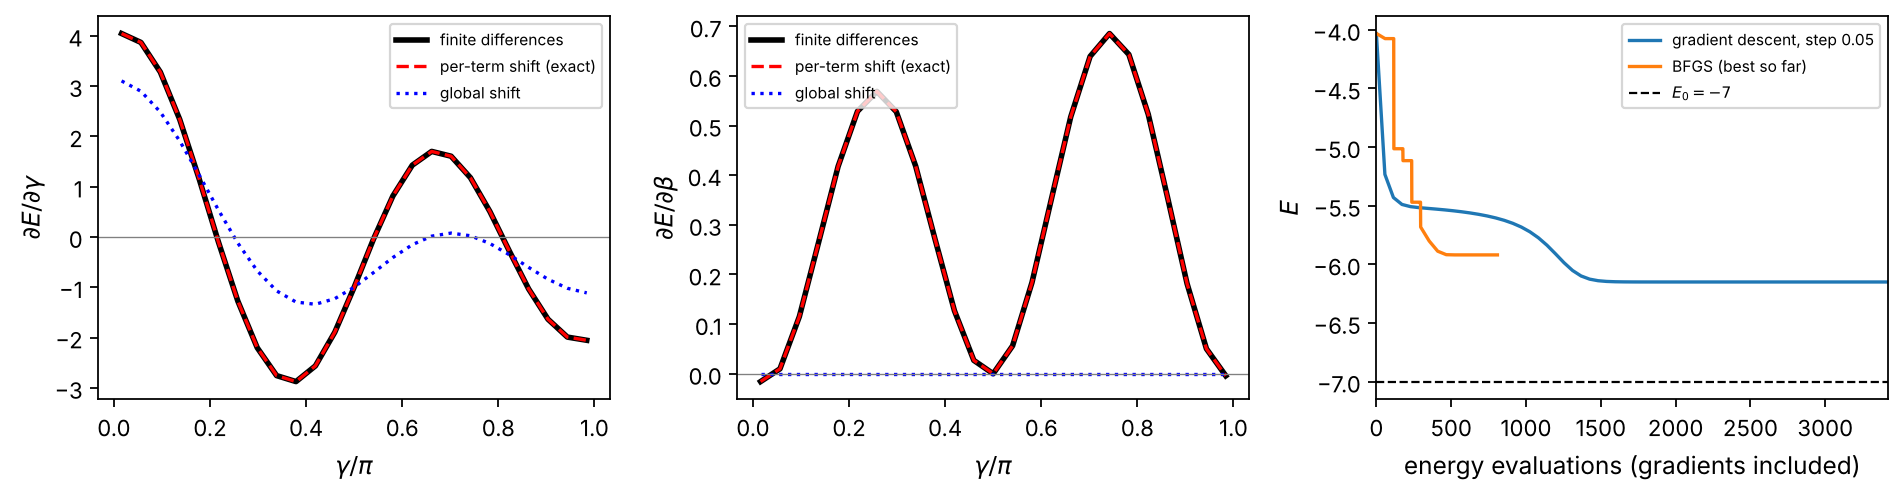

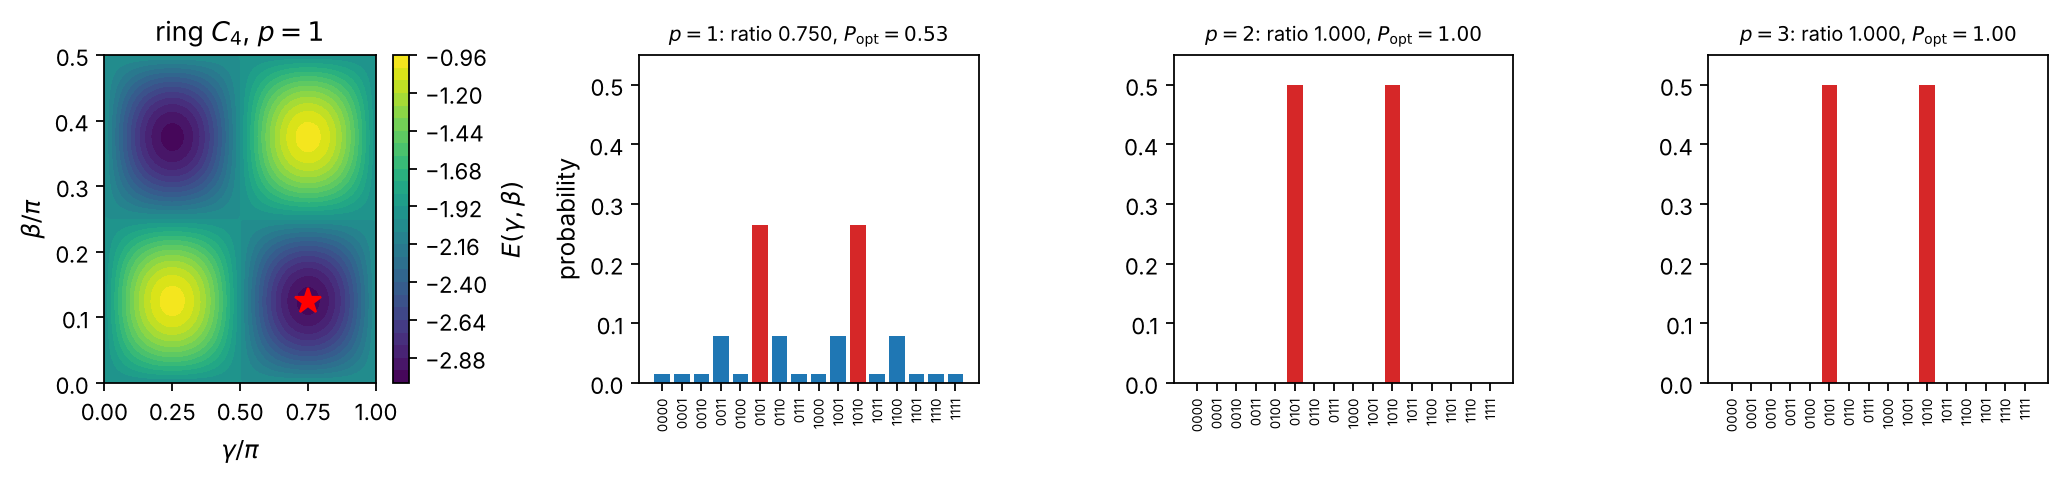

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/maxcut.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Exchange Hamiltonian, J = 1.0: eigenvalues [-0.75  0.25  0.25  0.25] (singlet -3J/4, triplet J/4)
  singlet amplitudes: [ 0.      0.7071 -0.7071  0.    ]  (|01> - |10>)/sqrt(2) up to sign
Cost Hamiltonian H_C = -(I - Z_L Z_R)/2: diagonal [ 0. -1. -1.  0.] (cut states |01>, |10> have energy -1)
  gate time for the cost unitary: t = 2 gamma / J; at gamma* = 3pi/2, t = 9.4248/J


  closed form -1/2 + sin(4 beta) sin(gamma)/2: max error 1.4e-15
  minimum E = -1.000000 at beta = pi/8, gamma = 3pi/2
  |<T0|psi*>|^2 = 1.000000: the optimal state is the triplet (|01>+|10>)/sqrt(2)
  |<S|psi*>|^2  = 0.000000: not the singlet ground state of H_ex


  optimum $(\gamma,\beta)=(3\pi/2,\pi/8)$: P = [0.  0.5 0.5 0. ], E = -1.0000
  off the optimum $(3\pi/2,\pi/16)$: P = [0.0732 0.4268 0.4268 0.0732], E = -0.8536
  100 shots at the optimum: counts [ 0 50 50  0], P(cut state) = 1.00


  p = 1: E* = -1.000000, ratio 1.0000, P(cut) = 1.0000
  p = 2: E* = -1.000000, ratio 1.0000, P(cut) = 1.0000
  p = 3: E* = -1.000000, ratio 1.0000, P(cut) = 1.0000
figures dwlandscape and dwprobs written


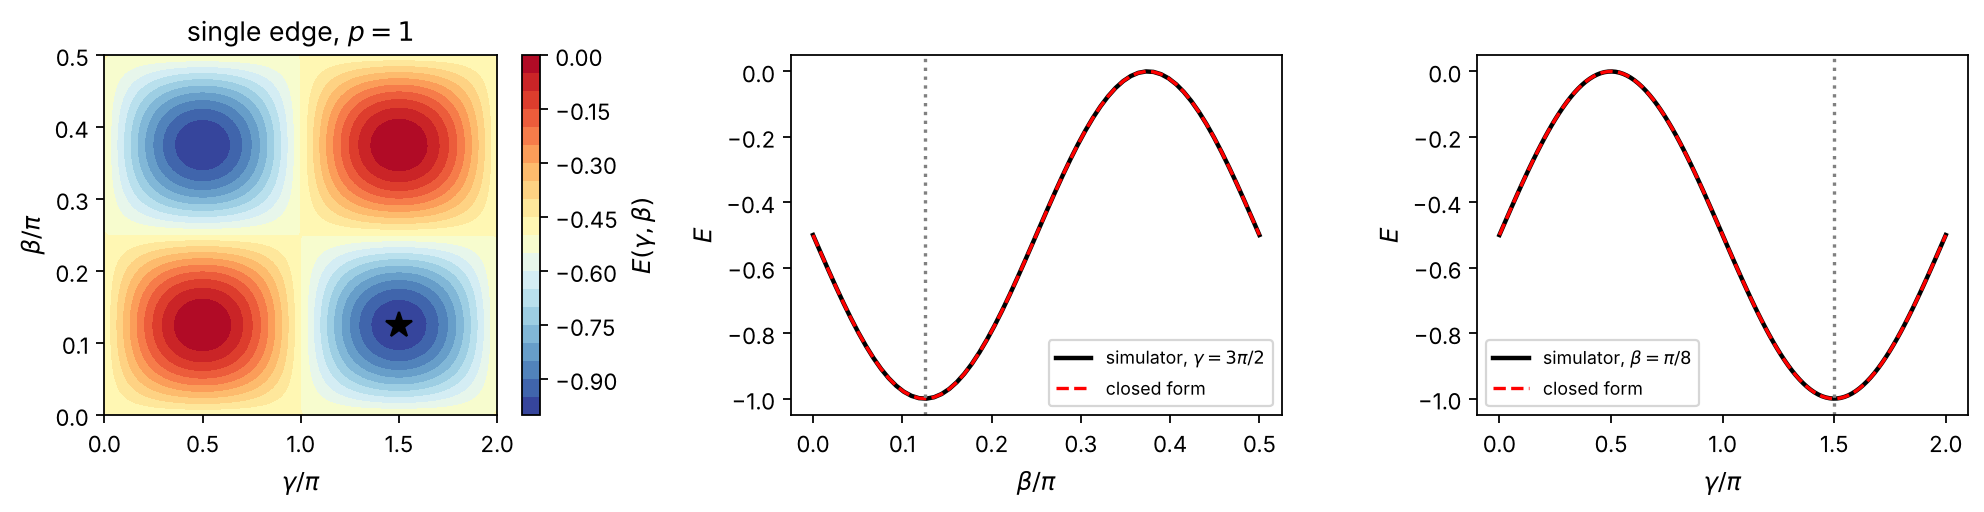

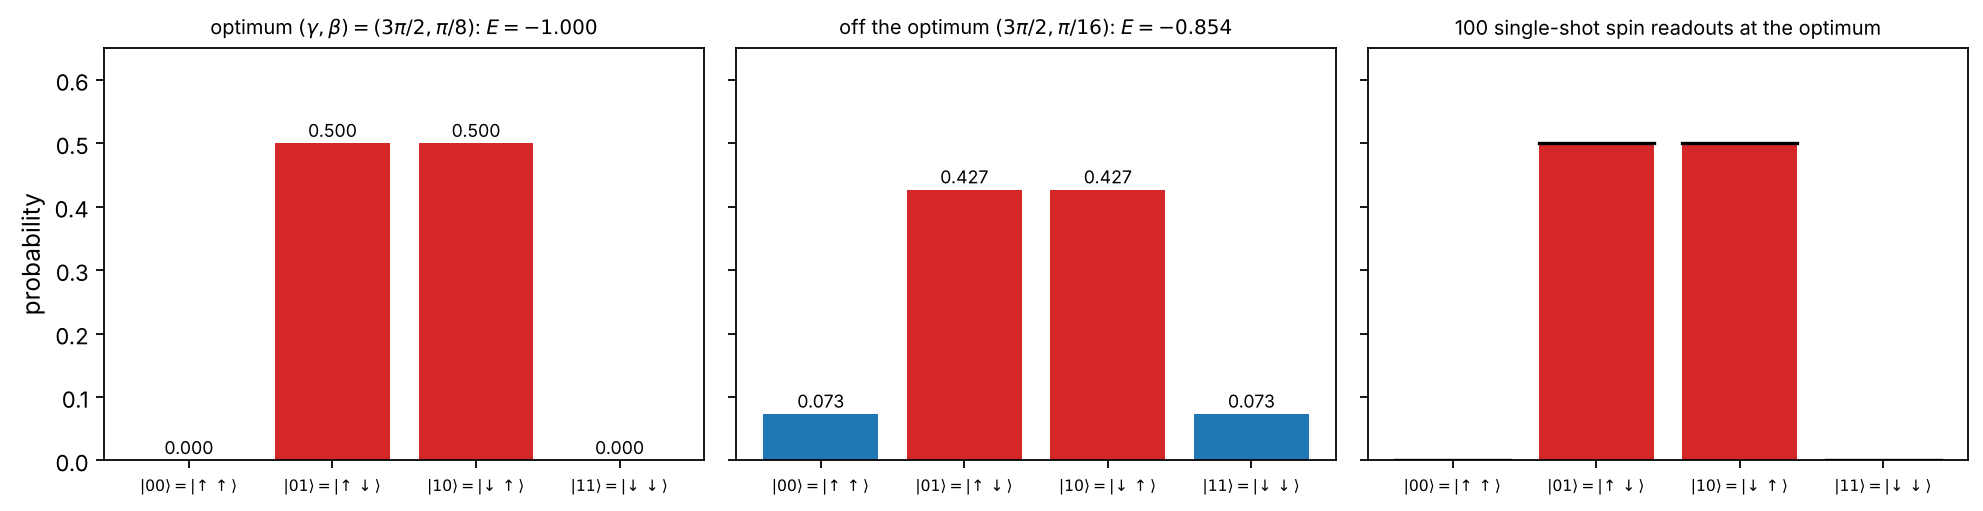

In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/double_well.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


S&P data: 164 weekly closes, 163 returns
  annualised mean return (%): [30.92 24.58 26.33 30.65]
  annualised volatility (%): [30.83 24.37 30.73 29.15]
  correlation matrix:
 [[1.    0.905 0.805 0.857]
 [0.905 1.    0.851 0.939]
 [0.805 0.851 1.    0.891]
 [0.857 0.939 0.891 1.   ]]



Synthetic data: lambda = 1.0, A = 0.3, K = 2
  QUBO diagonal: [-0.92 -0.92 -0.92 -0.96]
  Ising h: [-0.02  -0.015 -0.015 -0.   ]  J (upper): [0.16  0.155 0.165 0.16  0.155 0.16 ]  const 0.29500
  feasible portfolios (budget 2), Table 3-portfolio:
    B+D          0101  cost -0.060000
    C+D          0011  cost -0.040000
    A+D          1001  cost -0.020000
    A+C          1010  cost -0.020000
    B+C          0110  cost +0.000000
    A+B          1100  cost +0.000000
  ground state of H_C: E0 = -0.060000 at ['0101'] (= best feasible portfolio + penalty offset 0)
  energy of the uniform superposition +0.2950, spectrum [-0.0600, +1.3000]
  p=1: E = +0.07215  gap closed 0.628  P(optimal) 0.128  P(feasible) 0.738  most probable: B+D (0.128)


  p=2: E = -0.02102  gap closed 0.890  P(optimal) 0.172  P(feasible) 0.992  most probable: B+D (0.172)


  p=3: E = -0.02332  gap closed 0.897  P(optimal) 0.175  P(feasible) 0.998  most probable: B+D (0.175)


  p=4: E = -0.02502  gap closed 0.901  P(optimal) 0.202  P(feasible) 0.998  most probable: B+D (0.202)

S&P data: lambda = 2.0, A = 0.3, K = 2
  QUBO diagonal: [-1.0191  -1.02699 -0.97436 -1.03658]
  Ising h: [-0.16188 -0.13506 -0.18277 -0.15538]  J (upper): [0.21804 0.22631 0.22707 0.21378 0.21674 0.22986]  const 0.50329
  feasible portfolios (budget 2), Table 3-portfolio:
    MSFT+GOOG    0101  cost +0.003370
    AAPL+MSFT    1100  cost +0.026079
    AAPL+GOOG    1001  cost +0.052622
    MSFT+AMZN    0110  cost +0.053771
    AMZN+GOOG    0011  cost +0.108494
    AAPL+AMZN    1010  cost +0.111791
  ground state of H_C: E0 = +0.003370 at ['0101'] (= best feasible portfolio + penalty offset 0)
  energy of the uniform superposition +0.5033, spectrum [+0.0034, +2.4702]
  p=1: E = +0.15092  gap closed 0.705  P(optimal) 0.112  P(feasible) 0.646  most probable: MSFT+GOOG (0.112)


...

  p=4: E = +0.05185  gap closed 0.903  P(optimal) 0.259  P(feasible) 0.965  most probable: MSFT+GOOG (0.259)


  QAOA p=1 energy +0.15092 equals the thermal energy at beta_T ~ 2.4
  QAOA p=2 energy +0.08298 equals the thermal energy at beta_T ~ 6.4
  QAOA p=3 energy +0.07270 equals the thermal energy at beta_T ~ 8.1
  QAOA p=4 energy +0.05185 equals the thermal energy at beta_T ~ 14.5

Table 3-penalty (S&P data, p = 2): the penalty strength A


  A =  0.03: ground state 0001 (budget 1), P(feasible) 0.040, P(ground state) 0.233, P(MSFT+GOOG) 0.004


  A =  0.10: ground state 0001 (budget 1), P(feasible) 0.137, P(ground state) 0.222, P(MSFT+GOOG) 0.043


  A =  0.30: ground state 0101 (budget 2), P(feasible) 0.947, P(ground state) 0.153, P(MSFT+GOOG) 0.153
  A =  1.00: ground state 0101 (budget 2), P(feasible) 0.657, P(ground state) 0.146, P(MSFT+GOOG) 0.146
figures sp500data, portfolio and thermal written


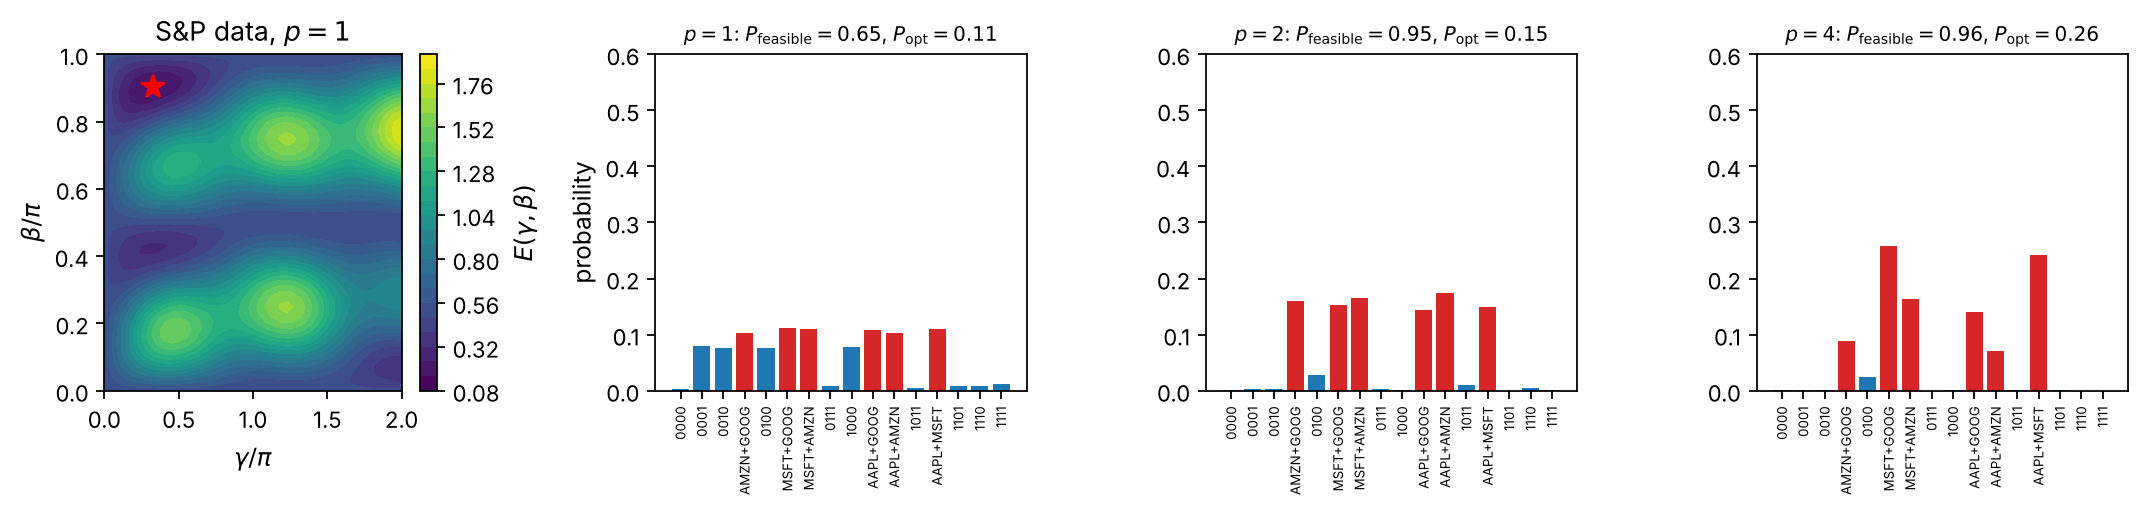

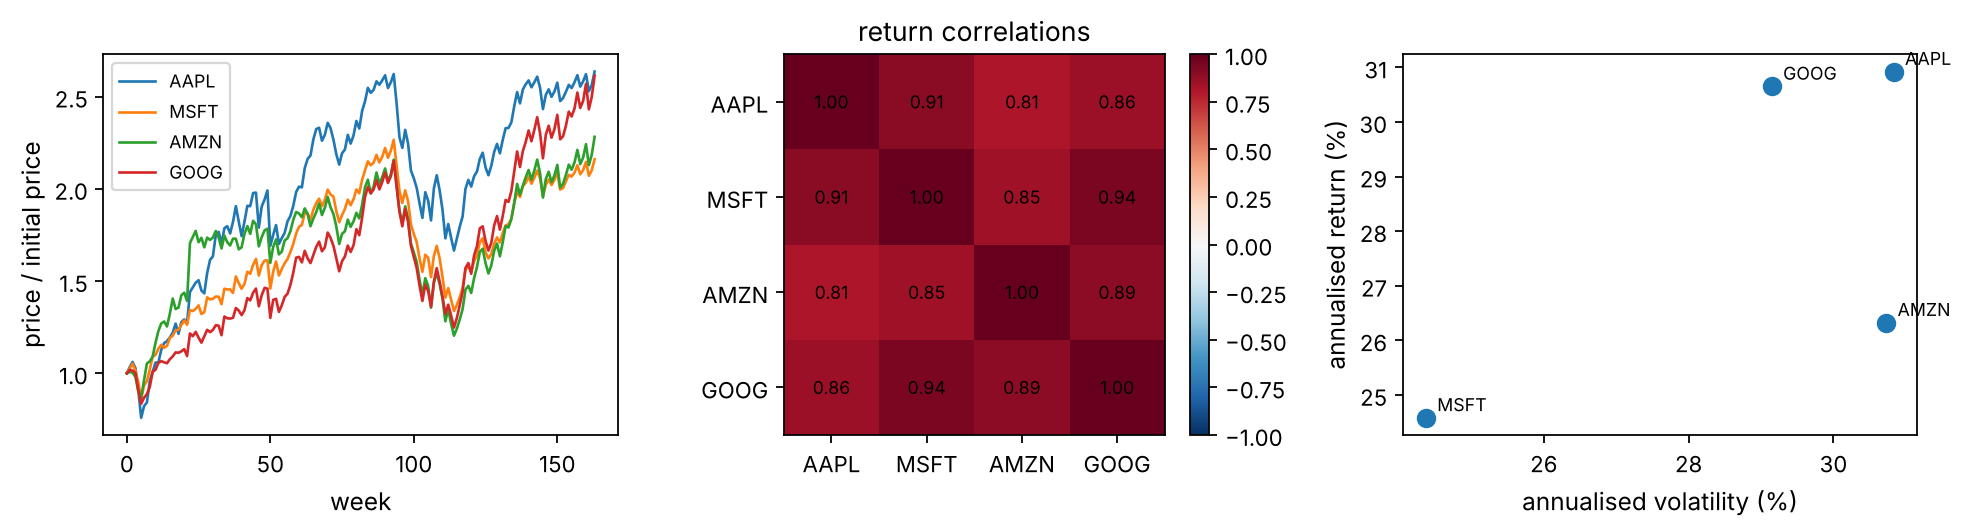

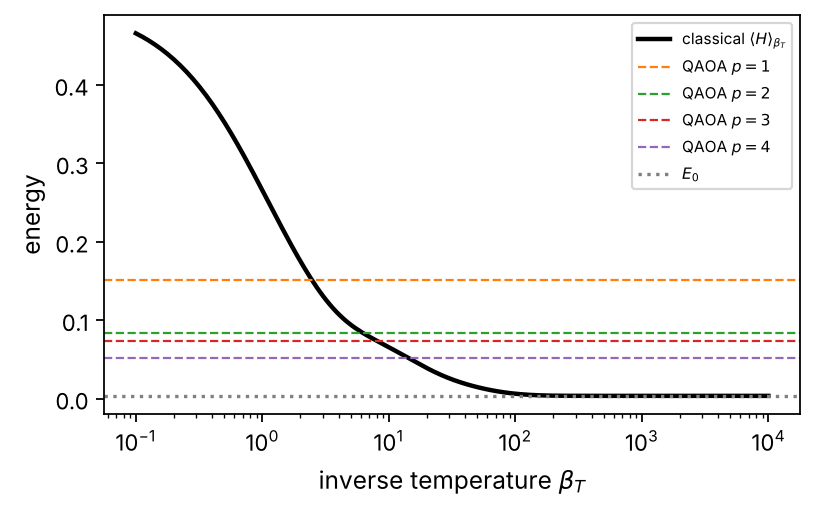

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/portfolio.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


8 points, 28 weighted edges; maximum cut 170.368 (scaled 24.561) at 00001111 and its complement
two-means clustering cuts 170.368: the same partition


  p=1: ratio 0.6026, P(optimal partition) 0.035, most probable string 10001111 (p = 0.027), cut 136.675


  p=2: ratio 0.7724, P(optimal partition) 0.266, most probable string 11110000 (p = 0.133), cut 170.368


  p=3: ratio 0.8992, P(optimal partition) 0.472, most probable string 00001111 (p = 0.236), cut 170.368


figure clustering written


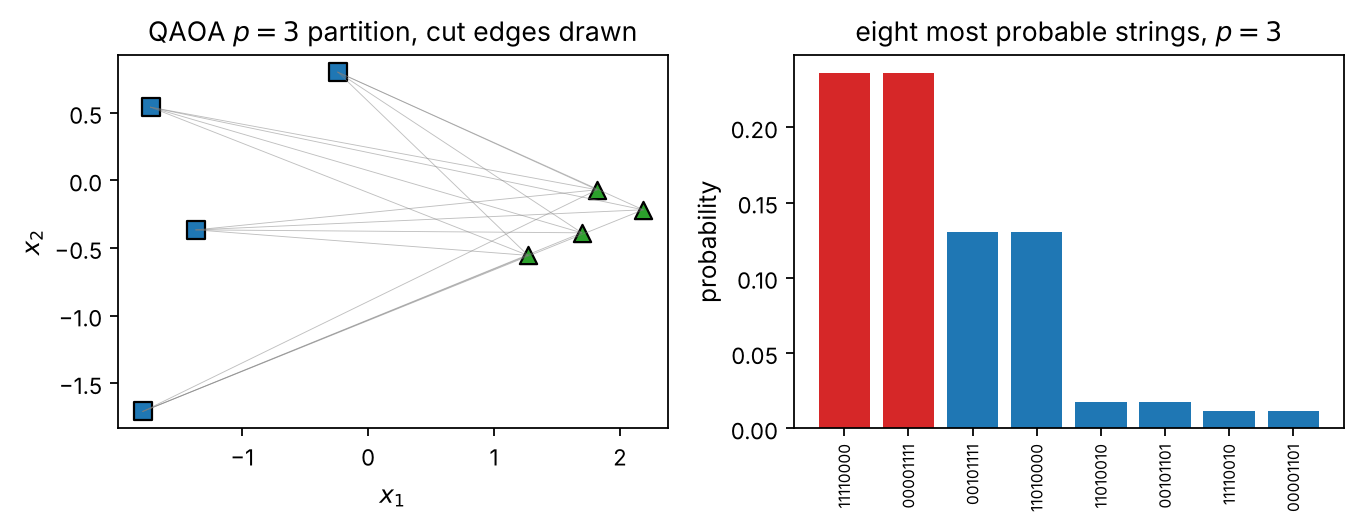

In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter3/clustering.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter3').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
